<a href="https://colab.research.google.com/github/Brayan-Garcia-Lopez/matematicas-avanzadas/blob/main/Practica_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Actividad 1. Preparación del entorno

In [1]:
# Importación de bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Establece una semilla para mejorar la reproducibilidad
keras.utils.set_random_seed(42)

# Muestra la versión instalada de TensorFlow
print("TensorFlow:", tf.__version__)

# Muestra las GPU disponibles
print("GPU disponibles:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponibles: []


Actividad 2. Carga del conjunto de datos

In [2]:
# Carga del dataset Fashion-MNIST
(x_train_original, y_train_original), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Muestra las dimensiones de los conjuntos
print("Entrenamiento original:", x_train_original.shape)
print("Prueba:", x_test.shape)
print("Forma de una imagen:", x_train_original[0].shape)
print("Valor mínimo:", x_train_original.min())
print("Valor máximo:", x_train_original.max())

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Entrenamiento original: (60000, 28, 28)
Prueba: (10000, 28, 28)
Forma de una imagen: (28, 28)
Valor mínimo: 0
Valor máximo: 255


Actividad 3. Visualización de imágenes

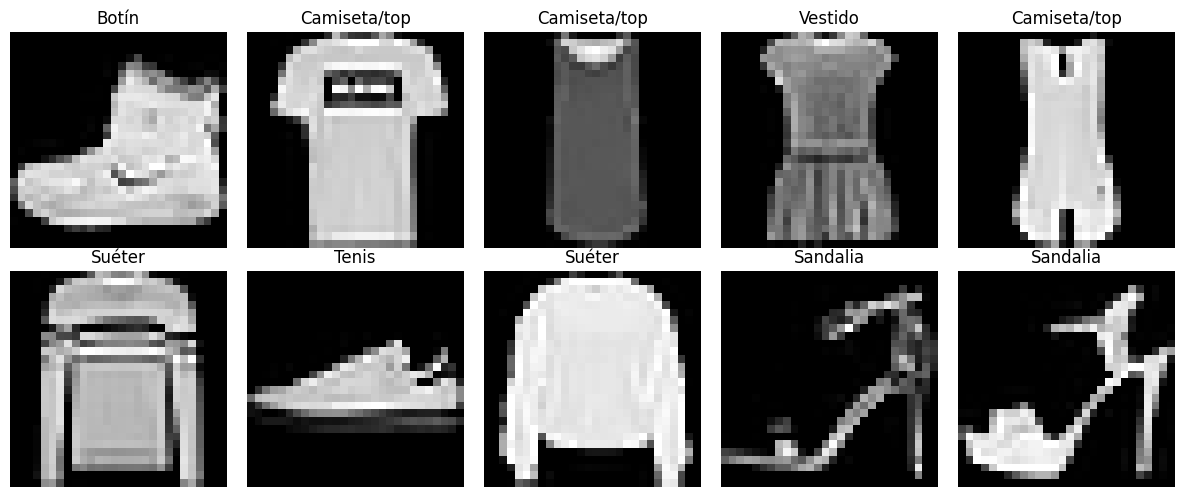

In [3]:
# Define los nombres de las diez categorías
nombres_clases = [
    "Camiseta/top",
    "Pantalón",
    "Suéter",
    "Vestido",
    "Abrigo",
    "Sandalia",
    "Camisa",
    "Tenis",
    "Bolso",
    "Botín"
]

# Visualiza las primeras 10 imágenes
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_original[i], cmap="gray")
    nombre = nombres_clases[y_train_original[i]]
    plt.title(nombre)
    plt.axis("off")
plt.tight_layout()
plt.show()

Actividad 4. Normalización de imágenes

In [4]:
# Normaliza los valores de píxeles al rango [0, 1]
x_train_original = x_train_original.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Mínimo normalizado:", x_train_original.min())
print("Máximo normalizado:", x_train_original.max())

Mínimo normalizado: 0.0
Máximo normalizado: 1.0


Actividad 5. División en entrenamiento y validación

In [5]:
# División del conjunto original en entrenamiento (80%) y validación (20%)
x_train, x_val, y_train, y_val = train_test_split(
    x_train_original,
    y_train_original,
    test_size=0.20,
    random_state=42,
    stratify=y_train_original
)

print("Entrenamiento:", x_train.shape)
print("Validación:", x_val.shape)
print("Prueba:", x_test.shape)

Entrenamiento: (48000, 28, 28)
Validación: (12000, 28, 28)
Prueba: (10000, 28, 28)


Actividad 6. Construcción de la red neuronal

In [6]:
# Construcción de la arquitectura MLP original
modelo = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

# Muestra el resumen del modelo
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Actividad 7. Compilación del modelo

In [7]:
# Configuración del proceso de entrenamiento
modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Actividad 8. Entrenamiento de la red neuronal

In [8]:
# Entrenamiento del modelo original
historial = modelo.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=128,
    validation_data=(x_val, y_val),
    verbose=1
)

Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.7975 - loss: 0.5780 - val_accuracy: 0.8356 - val_loss: 0.4603
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8543 - loss: 0.4054 - val_accuracy: 0.8494 - val_loss: 0.4130
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8703 - loss: 0.3602 - val_accuracy: 0.8710 - val_loss: 0.3640
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8777 - loss: 0.3332 - val_accuracy: 0.8798 - val_loss: 0.3393
Epoch 5/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8856 - loss: 0.3117 - val_accuracy: 0.8845 - val_loss: 0.3266
Epoch 6/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8915 - loss: 0.2945 - val_accuracy: 0.8847 - val_loss: 0.3240
Epoch 7/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8961 - loss: 0.2808 - val_accuracy: 0.8870 - val_loss: 0.3244
Epoch 8/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8998 - loss: 0.2675 - val_accuracy: 0

Actividad 9. Visualización de las curvas de aprendizaje

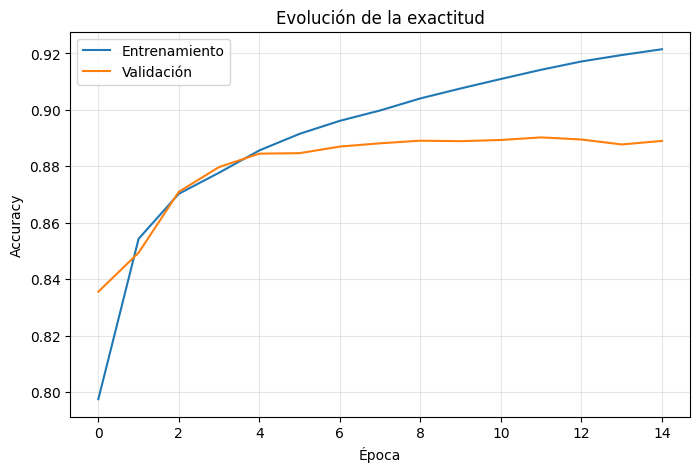

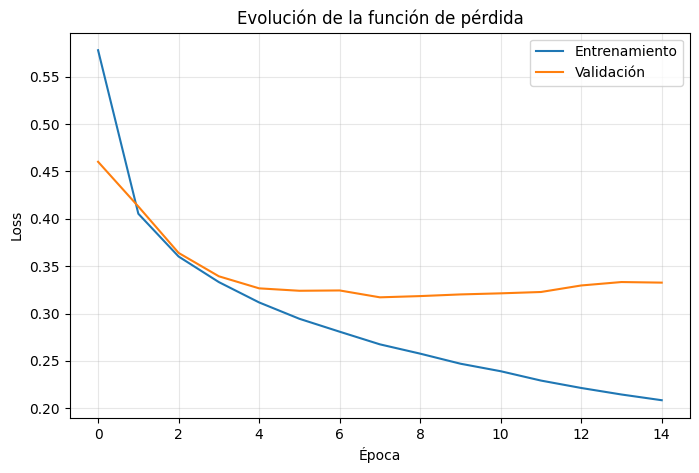

In [9]:
# Recupera el historial
historia = historial.history

# Gráfica de Exactitud (Accuracy)
plt.figure(figsize=(8, 5))
plt.plot(historia["accuracy"], label="Entrenamiento")
plt.plot(historia["val_accuracy"], label="Validación")
plt.title("Evolución de la exactitud")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Gráfica de Pérdida (Loss)
plt.figure(figsize=(8, 5))
plt.plot(historia["loss"], label="Entrenamiento")
plt.plot(historia["val_loss"], label="Validación")
plt.title("Evolución de la función de pérdida")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Actividad 10. Evaluación del modelo

In [10]:
# Evaluación en el conjunto de prueba
perdida_test, accuracy_test = modelo.evaluate(x_test, y_test, verbose=0)
print("Pérdida en prueba:", perdida_test)
print("Accuracy en prueba:", accuracy_test)

# Genera predicciones
probabilidades = modelo.predict(x_test, verbose=0)
y_pred = np.argmax(probabilidades, axis=1)

# Exactitud calculada con Scikit-learn
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy calculada:", accuracy)

# Reporte de clasificación por categoría
print("\nReporte de Clasificación:")
print(classification_report(
    y_test,
    y_pred,
    labels=list(range(10)),
    target_names=nombres_clases,
    zero_division=0
))

Pérdida en prueba: 0.36344045400619507
Accuracy en prueba: 0.8794000148773193
Accuracy calculada: 0.8794

Reporte de Clasificación:
              precision    recall  f1-score   support

Camiseta/top       0.86      0.81      0.84      1000
    Pantalón       0.98      0.98      0.98      1000
      Suéter       0.76      0.80      0.78      1000
     Vestido       0.87      0.89      0.88      1000
      Abrigo       0.74      0.87      0.80      1000
    Sandalia       0.97      0.95      0.96      1000
      Camisa       0.77      0.61      0.68      1000
       Tenis       0.92      0.96      0.94      1000
       Bolso       0.97      0.97      0.97      1000
       Botín       0.97      0.94      0.95      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



Actividad 11. Matriz de confusión

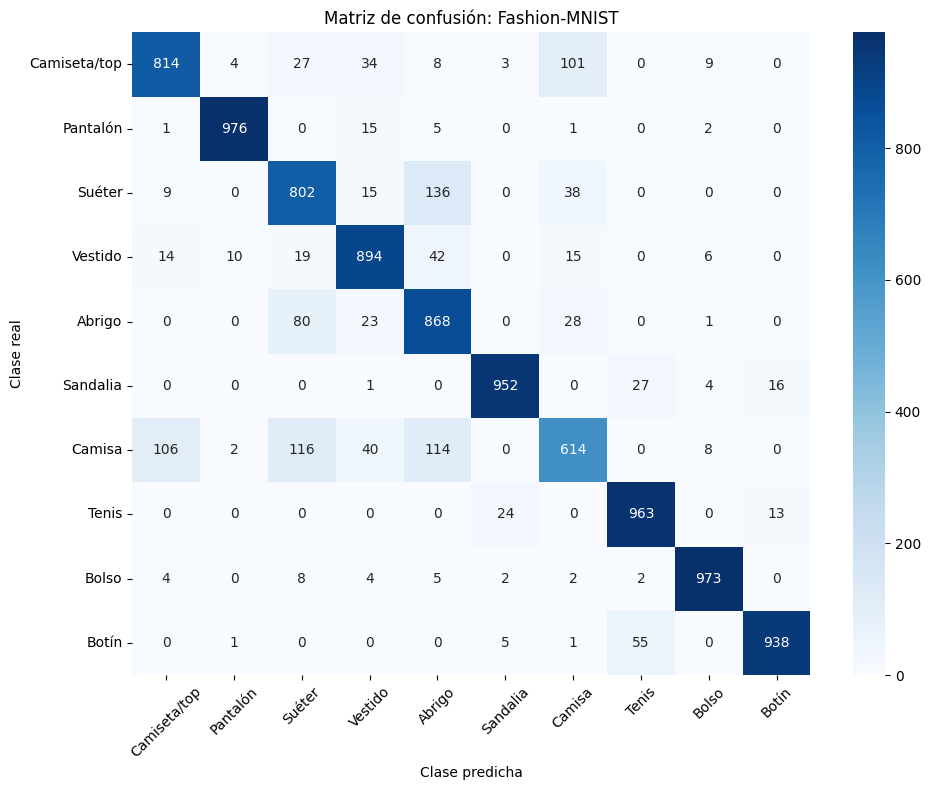

In [11]:
# Matriz de confusión
matriz = confusion_matrix(y_test, y_pred, labels=list(range(10)))

plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nombres_clases,
    yticklabels=nombres_clases
)
plt.title("Matriz de confusión: Fashion-MNIST")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Actividad 12. Visualización de predicciones

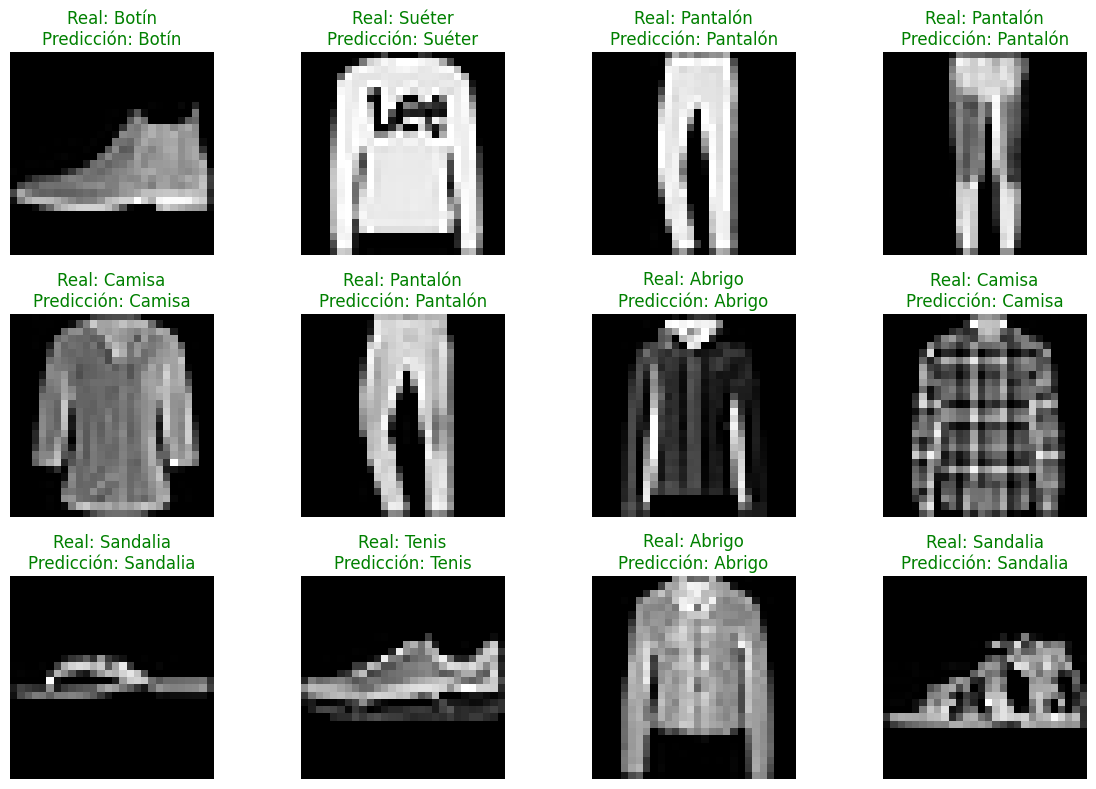

In [12]:
# Muestra 12 predicciones de prueba con código de color
plt.figure(figsize=(12, 8))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    real = nombres_clases[y_test[i]]
    predicha = nombres_clases[y_pred[i]]
    color = "green" if y_test[i] == y_pred[i] else "red"
    plt.title(f"Real: {real}\nPredicción: {predicha}", color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()

Actividad 13. Guardado del modelo

In [13]:
# Guardar el modelo en formato Keras
modelo.save("modelo_fashion_mnist_mlp.keras")
print("Modelo guardado correctamente.")

Modelo guardado correctamente.


Actividad (Reto). Selección automática de componentes y comparación

In [16]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import numpy as np


n_muestras = 10000
X_escalado = x_train[:n_muestras].reshape(n_muestras, -1)
etiquetas_original = y_train[:n_muestras]

umbral = 0.90
pca_reto = PCA(n_components=umbral)
X_reto = pca_reto.fit_transform(X_escalado)

n_componentes = pca_reto.n_components_
varianza_retenida = pca_reto.explained_variance_ratio_.sum()

print("Componentes seleccionados:", n_componentes)
print("Varianza conservada:", varianza_retenida)

modelo_reto = KMeans(
    n_clusters=10,  # Fashion-MNIST tiene 10 clases reales
    n_init=10,
    random_state=42
)
etiquetas_reto = modelo_reto.fit_predict(X_reto)

# Calculamos las métricas
silueta_reto = silhouette_score(X_reto, etiquetas_reto)
ari_reto = adjusted_rand_score(etiquetas_original, etiquetas_reto)

print("Silueta del modelo reducido:", silueta_reto)
print("ARI respecto al modelo original:", ari_reto)

Componentes seleccionados: 83
Varianza conservada: 0.90050113
Silueta del modelo reducido: 0.18741125
ARI respecto al modelo original: 0.34870255046690446
